# Lab 3 - Deep Learning
## Ava Everett (49136678) and Jay Lu (49200794)

## Deep Learning Framework. 
*Demonstrate conceptual understanding of a deep learning workflow. Without assistance from an LLM, explain the role of the following PyTorch components:*

- **Dataset (in Pytorch)**: An abstract class that represents the imported dataset. Argument of the DataLoader constructor; stores every sample from the data and its respective labels. There are two types of datasets: map-style datasets and iterable-style datasets. 
- **Data Loader**: A class that allows the program to iterate through a dataset in determined batches. It also provides the framework to use a variety of multiprocessing functions, and it can be used to train a model.
- **Model Class (nn.Module)**: The base class for all neural network modules; registers parameters and, if they have weights, will express them via instances of torch.nn.Parameter. Has an init and forward function for initialization and computation, respectively.
- **Loss Function**: Measure how well the model's predicted value is to the target value. Can be used to optimize output and gauge how well/poorly a model is doing. 
- **Optimizer**: A specific version of an optimization algorithm to update a neural network's parameters. There are a few available in PyTorch (e.g., Adam, Adagrad, SGD), but you can build your own custom optimizer for specific problems.
- **Training Loop (Providing Training Data to Model)**: Feeds the sample data to the model for the optimizer to tune the model's parameters. Works by grabbing a batch of data from the DataLoader, performs its predictions, calculates the loss on the predictions and the actual data, backpropagates, adjusts the model's learning weights based on the new observations, and reports the loss. It works in epochs, which are passes through the entire dataset, validating and saving a copy of the model each time. Model must be set to training mode during this time. 
- **Validation Loop (Providing Data to Evaluate the Model)**: Is inside the epoch loop, only does a forward pass and loss calculation (aka: no backprop). Helps with detection of overfitting, tuning hyperparameters, and letting the user see when is the best point to stop the training of the model. Model must be set to evaluation mode during this time. 

## Training Pipeline
*Using an LLM, generate starter code that constructs the training pipeline for your dataset and model. The pipeline should allow at least two ways of providing data to your model: (1) all data can be provided to a model as a single input and (2) modalities of data can be provided to the model as separate parallel inputs. When using an LLM, you should provide the prompt used, identify one aspect of the generated pipeline that was modified by your team, and explain why the modification was necessary.*

In [1]:
# importing dataset - Anime Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print ('Pandas:', pd.__version__)
print('Numpy:', np.__version__)

df = pd.read_csv('https://raw.githubusercontent.com/Lu-Rin-e/CS5324-Machine-Learning-Labs/refs/heads/main/anime_dataset_20k.csv')
df.head()

Pandas: 3.0.6
Numpy: 2.5.3


,mal_id,anilist_id,title_english,title_romaji,title_japanese,title_synonyms,type,source,status,age_rating,...,is_disney_plus,is_hulu,is_vrv,is_bilibili,is_youtube,num_platforms,score_tier,popularity_tier,synopsis,image_url
0,1,1.0,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,NaN,TV,original,finished_airing,r,...,False,True,False,False,False,6,Great,Top 100,"Crime is timeless. By the year 2071, humanity ...",https://cdn.myanimelist.net/images/anime/4/196...
1,5,5.0,Cowboy Bebop: The Movie,Cowboy Bebop: Tengoku no Tobira,カウボーイビバップ 天国の扉,Cowboy Bebop: Knockin' on Heaven's Door,MOVIE,original,finished_airing,r,...,False,False,False,False,False,0,Great,Top 1K,"Another day, another bounty—such is the life o...",https://cdn.myanimelist.net/images/anime/1439/...
2,6,6.0,Trigun,Trigun,トライガン,NaN,TV,manga,finished_airing,pg_13,...,False,False,False,False,False,1,Great,Top 500,"Vash the Stampede is the man with a $$60,000,0...",https://cdn.myanimelist.net/images/anime/1130/...
3,7,7.0,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),WHR,TV,original,finished_airing,pg_13,...,False,False,False,False,False,1,Good,Top 5K,"Though hidden away from the general public, Wi...",https://cdn.myanimelist.net/images/anime/10/19...
4,8,8.0,Beet the Vandel Buster,Bouken Ou Beet,冒険王ビィト,Adventure King Beet,TV,manga,finished_airing,pg,...,False,False,False,False,False,0,Average,Niche,It is the dark century and the people are suff...,https://cdn.myanimelist.net/images/anime/7/215...


Our main goal will be to get the model to accurately predict the popularity tier of a show (e.g., Niche, Top 5K, Top 1k, Top 500, and Top 100). 

Since just about all of the non tv/movies are niche, this set will isolate tv shows and movies. We will also remove all adult/explicit anime.

In [2]:
# Removing Adult/Explicit Anime
df = df[df.is_adult == False]

#Removing is_adult column
del df['is_adult']

# Removing all items that aren't TV shows or Movies
df = df[(df.type == 'TV') | (df.type == 'MOVIE')]

Let's see the split of the data

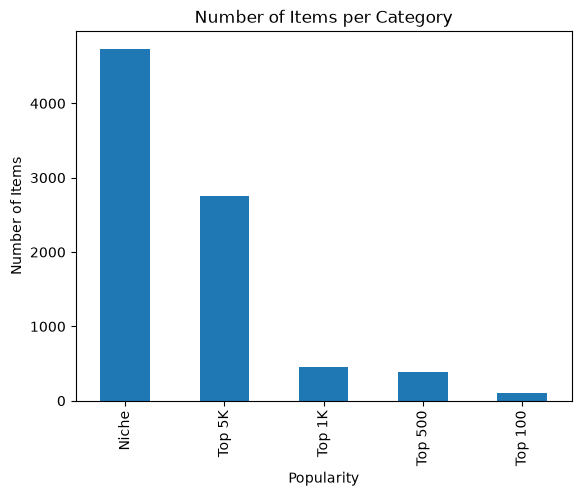

In [3]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

We'll be consolidating Top 1K, Top 500, and Top 100 into one category, as they are too small by themselves.

In [4]:
df['popularity_tier'] = df['popularity_tier'].replace('Top 100', 'Top 1K')
df['popularity_tier'] = df['popularity_tier'].replace('Top 500', 'Top 1K')

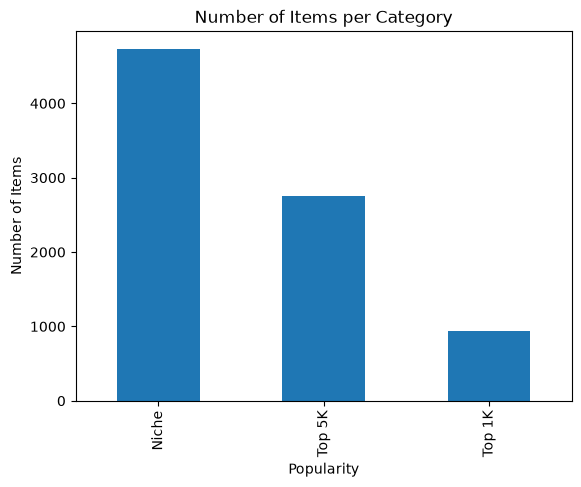

In [5]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

With that settled, let's start cleaning up the data more. 

1 - As we're predicting popularity, all popularity-related categories must be removed to prevent data leaking (aka: MAL popularity, MAL members, MAL favorites, anilist popularity, anilist favorites). All non-relevant categories/difficult to parse categories will also be removed (ie: anime title, synopsis, etc.)
2 - We need to multi-hot encode the genres AND convert score_tier and popularity_tier to integers

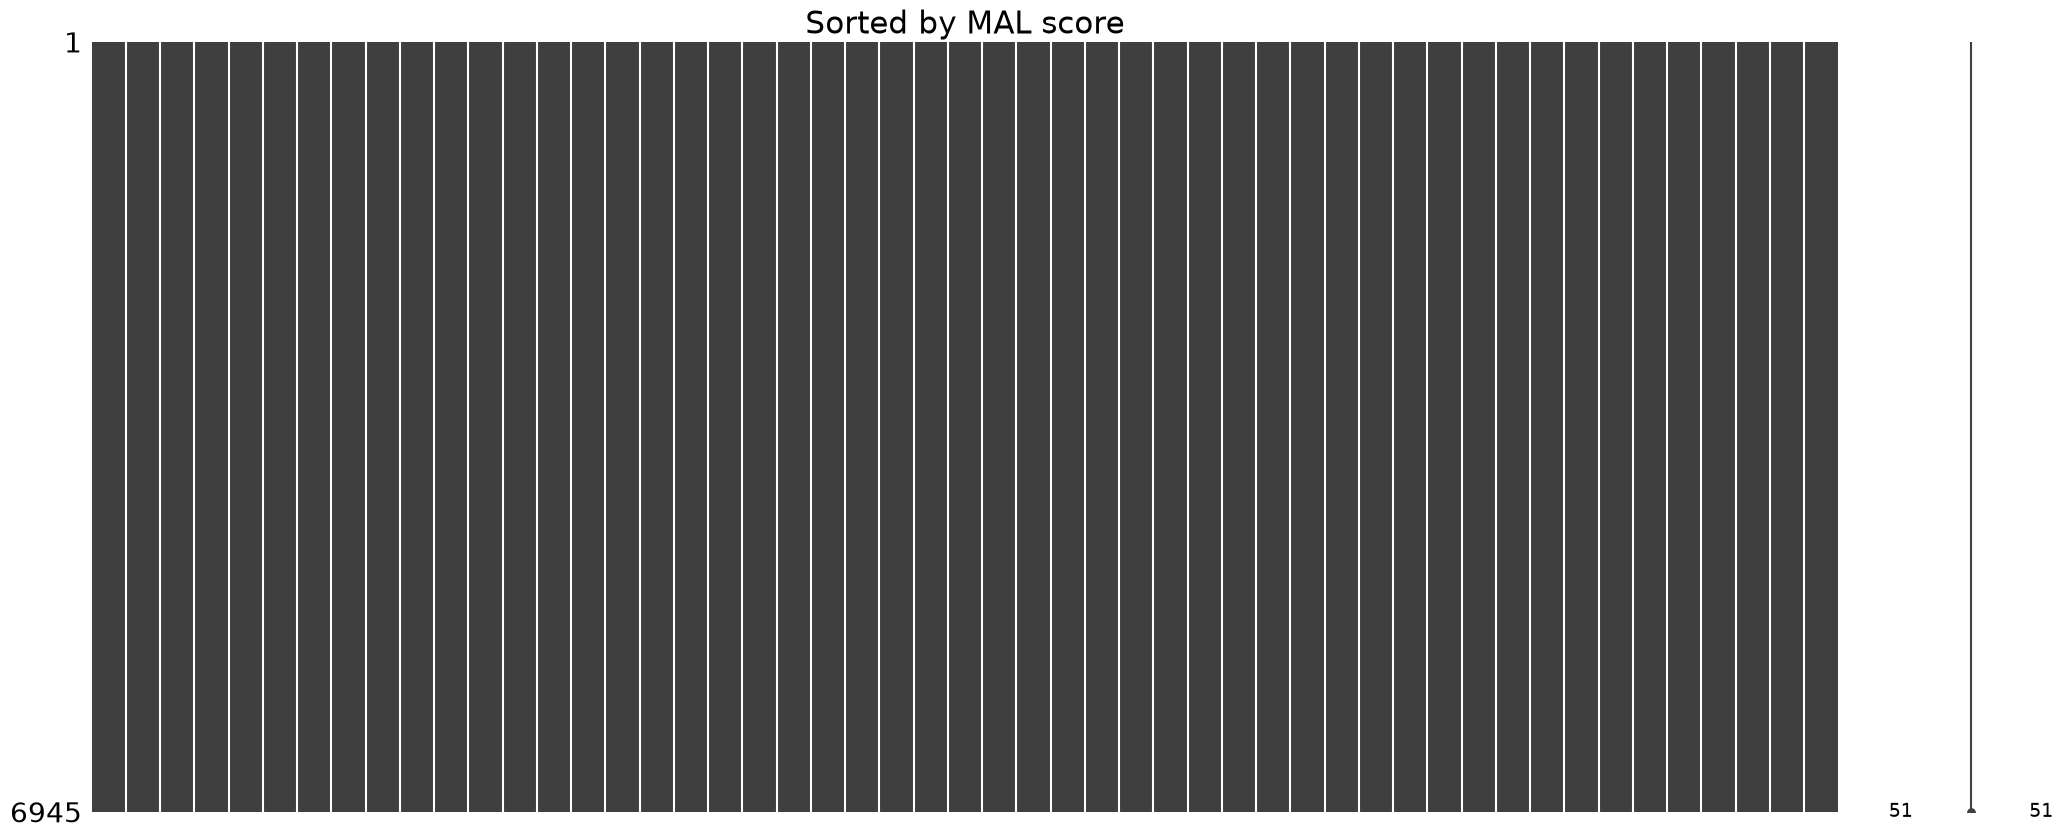

In [6]:
keep_cols = ['type', 'source', 'status','age_rating','season', 'year', 'episodes','duration_min', 'mal_score', 'anilist_score', 'score_gap_mal_anilist','studio_main', 'num_platforms', 'score_tier', 'popularity_tier', 'genres']
df = df[keep_cols]
# Drop rows with missing values
df = df.dropna(subset=keep_cols)
#Multi-hot Encoding the Genres; they are currently one object
from sklearn.preprocessing import MultiLabelBinarizer

genre_lists = df['genres'].str.split('|').apply(lambda lst: [g.strip() for g in lst])

mlb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb.fit_transform(genre_lists),
    columns=mlb.classes_,
    index=df.index
)

# The dataset combined MAL Themes, MAL Genres, and Demographics into genres. Just keeping the Genres and Demographics
genres_to_keep = [
    'Action', 'Adventure', 'Avant Garde', 'Boys Love',
    'Comedy', 'Drama', 'Fantasy', 'Girls Love', 'Gourmet', 'Horror',
    'Mystery', 'Romance', 'Sci-Fi', 'Slice of Life', 'Sports',
    'Supernatural', 'Suspense', 'Josei', 'Kids', 'Seinen', 'Shoujo', 'Shounen'
]

# Filtering the encoded columns before merging into dataframe
genre_encoded = genre_encoded[[col for col in genre_encoded.columns if col in genres_to_keep]]

df = pd.concat([df, genre_encoded], axis=1)



#Getting rid of old genres column
del df['genres']


# One-hot encode type and source (currently strings)
df = pd.get_dummies(df, columns=['type', 'source'], drop_first=True)

#Encode popularity tier and score tier

score_map = {"Poor": 0, "Average": 1, "Good": 2, "Great": 3, "Masterpiece": 4}


df["score_tier_int"] = df["score_tier"].map(score_map)


#Now, we can remove the old score tier
del df['score_tier']


#Checking what the cleaned data looks like
df.to_csv('animecleaned3.csv', index=False)

#Checking to make sure there is no missing data
import missingno as mn
mn.matrix(df.sort_values(by=['mal_score']))
plt.title("Sorted by MAL score", fontsize=22)
plt.show()



With all the data cleaned, let's move on to creating the pipeline!

Agent Used: Microsoft Copilot GPT 6 - Luna

*Prompt:* "I am making a deep learning algorithm to calculate whether an anime is one of three options in the popularity_tier column (niche, top 5k, or top 1k). Create a pipeline for the cleaned dataset so that it can be provided to a model as a single input and modalities of data can be provided to the model as separate parallel inputs. Add this pipeline to a new cell below this one."

**LLM-Generated Code:**

When looking at this, I noticed the code decided to encode studio_main without grouping any of the values. The problem with this is that there are a wide variety of studios, including ones that are only mentioned once. The best way to handle this would be to start grouping smaller studios that have only made one or two shows to not have too many rows

Agent Used: Claude Sonnet 5.5 Medium

*Prompt:* There are a kajillion version of studio_main. Should I keep it in, and does the code above handle it properly, as it has not been onehotencoded?

**Response:**



Two quick corrections, then the recommendation.

The code does one-hot encode it. studio_main is in categorical_cols, so OneHotEncoder expands it into one column per unique studio, learned from the training set. So it “works,” but crudely. With thousands of studios, you’d get thousands of mostly-zero columns for about 6,700 training rows, and most studios would appear only once or twice. The network can’t learn anything reliable from a studio it has seen twice, and the extra width encourages overfitting. Also, any validation studio not seen in training is silently set to all zeros.

Should you keep it? Yes. Studio is probably one of your strongest signals (Toei, Madhouse, and Kyoto Animation titles tend to get more attention than obscure one-off studios), so dropping it would cost you real predictive power. The fix is to reduce the cardinality, not remove the feature.

Step 1: Clean the strings (before the split). Your data has inconsistent casing (I saw bones and MADHOUSE in the rows I looked at), so merge near-duplicates first:

python
df["studio_main"] = df["studio_main"].fillna("Unknown").astype(str).str.strip().str.lower()
print(df["studio_main"].value_counts().head(30))
print((df["studio_main"].value_counts() >= 20).sum(), "studios have 20+ titles")

Cleaning isn’t leakage, since it doesn’t use the labels or validation statistics.

Step 2, Option A (simplest): group rare studios in the encoder. One change to your existing line:

python
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)

Any category appearing fewer than 20 times in the training data is merged into a single “infrequent” column, and unseen validation studios are routed there too. This requires scikit-learn 1.1 or newer. Because the encoder is fit on training data only, there’s no leakage. Note that min_frequency applies to all of categorical_cols, which is fine for status, season, and age_rating, though it may merge a rare age rating.

Step 2, Option B (better for deep learning): use an embedding. Since you already have a parallel-inputs design, you can give studio its own branch. Map each studio to an integer ID, with 0 reserved for rare or unseen studios:

python
counts = train_df["studio_main"].value_counts()
keep = counts[counts >= 20].index
studio_to_id = {s: i + 1 for i, s in enumerate(keep)}   # 0 = rare/unknown

studio_train = train_df["studio_main"].map(studio_to_id).fillna(0).astype(np.int64).to_numpy()
studio_val = val_df["studio_main"].map(studio_to_id).fillna(0).astype(np.int64).to_numpy()

Then add a studio tensor (as torch.long) to your dataset’s modalities, remove studio_main from categorical_cols, and in the model feed it through nn.Embedding(len(keep) + 1, 8) before concatenating with the other branches. Note that the long tensor can’t be concatenated into the single float feature tensor, so this option only works with use_parallel_inputs = True unless you convert it to float or adjust the dataset. The embedding lets similar studios end up with similar vectors, which one-hot can’t do.

Which one? Start with Option A, since it’s a one-line change and gives a clean baseline. Try Option B if you want to show off what deep learning adds. Either way, pick the threshold (20 is a starting guess) by looking at the value_counts() output. And if you compare both, keep everything else fixed so the difference is attributable to the studio encoding.

In [7]:
#Let's onehotencode studio_main.
#First, merging near-dupes
df["studio_main"] = df["studio_main"].fillna("Unknown").astype(str).str.strip().str.lower()

#Now let's tweak the generated code to handle this

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Target indices: Niche=0, Top 5K=1, Top 1K=2.
label_map = {"niche": 0, "top 5k": 1, "top 1k": 2}
y_names = df["popularity_tier"].astype(str).str.strip().str.lower()
unknown = sorted(set(y_names) - set(label_map))
if unknown:
    raise ValueError(f"Unexpected popularity_tier values: {unknown}")
y = y_names.map(label_map).to_numpy(dtype=np.int64)

numeric_cols = ["year", "episodes", "duration_min", "mal_score", "anilist_score",
                "score_gap_mal_anilist", "num_platforms"]
categorical_cols = ["status", "age_rating", "season", "studio_main"]
binary_cols = [c for c in df if c.startswith(("type_", "source_"))]
genre_cols = ["Action", "Adventure", "Avant Garde", "Boys Love", "Comedy", "Drama",
              "Fantasy", "Girls Love", "Gourmet", "Horror", "Josei", "Kids",
              "Mystery", "Romance", "Sci-Fi", "Seinen", "Shoujo", "Shounen",
              "Slice of Life", "Sports", "Supernatural", "Suspense"]
required = numeric_cols + categorical_cols + binary_cols + genre_cols + ["popularity_tier"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing cleaned-data columns: {missing}")

# Split before fitting transforms to prevent validation-data leakage.
train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                      random_state=42, stratify=y)
train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

scaler = StandardScaler()
numeric_train = scaler.fit_transform(train_df[numeric_cols]).astype(np.float32)
numeric_val = scaler.transform(val_df[numeric_cols]).astype(np.float32)
## LINE EDIT: Changing the OneHotEncoder to handle infrequent categories instead of ignoring them

encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)


category_train_encoded = encoder.fit_transform(train_df[categorical_cols]).toarray()
category_val_encoded = encoder.transform(val_df[categorical_cols]).toarray()
category_train = np.concatenate((category_train_encoded,
                                 train_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
category_val = np.concatenate((category_val_encoded,
                               val_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
genre_train = train_df[genre_cols].to_numpy(dtype=np.float32)
genre_val = val_df[genre_cols].to_numpy(dtype=np.float32)
y_train, y_val = y[train_idx], y[val_idx]

class AnimeDataset(Dataset):
    """Yield one concatenated tensor or separate tensors for each modality."""
    def __init__(self, numeric, categorical, genres, labels, input_mode="single"):
        if input_mode not in ("single", "parallel"):
            raise ValueError("input_mode must be 'single' or 'parallel'")
        self.input_mode = input_mode
        self.modalities = {
            "numeric": torch.tensor(numeric, dtype=torch.float32),
            "categorical": torch.tensor(categorical, dtype=torch.float32),
            "genres": torch.tensor(genres, dtype=torch.float32),
        }
        self.features = torch.cat(list(self.modalities.values()), dim=1)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        if self.input_mode == "parallel":
            return {name: values[index] for name, values in self.modalities.items()}, self.labels[index]
        return self.features[index], self.labels[index]

train_dataset_single = AnimeDataset(numeric_train, category_train, genre_train, y_train)
val_dataset_single = AnimeDataset(numeric_val, category_val, genre_val, y_val)
train_dataset_parallel = AnimeDataset(numeric_train, category_train, genre_train, y_train, "parallel")
val_dataset_parallel = AnimeDataset(numeric_val, category_val, genre_val, y_val, "parallel")

# True gives batches of modality tensors; False gives one concatenated feature tensor.
use_parallel_inputs = True
train_dataset = train_dataset_parallel if use_parallel_inputs else train_dataset_single
val_dataset = val_dataset_parallel if use_parallel_inputs else val_dataset_single
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

print("Class mapping:", label_map)
print("Train/validation rows:", len(train_dataset), len(val_dataset))
print("Single input width:", train_dataset_single.features.shape[1])
print("Parallel modality widths:", {name: x.shape[1] for name, x in train_dataset_parallel.modalities.items()})


ModuleNotFoundError: No module named 'torch'

## Model Construction

*You may use an LLM to help generate model code, assuming you verify all generated code and explain architectural decisions in your own words.*

 - *Single modality Input: Construct a single input feedforward neural network using PyTorch or Keras for your dataset. The network should contain*
    - input layer
    - at least two hidden layers (likely more are needed)
    - output layer
    - nonlinear activation functions
- *Multiple Modality Input: Construct a similar model that takes multiple inputs as separate modalities. These modalities should be processed separately (i.e., with a hidden layer for that modality or an embedding layer for each modality) before the representations are combined and processed for the remainder of the network. This is similar to we processed each modality of categorical data in class.*
- *Optional: Instead of single- and multi-modality, teams can also investigate the multi- versus crossed-models (i.e., wide and deep)*
- *Teams must investigate three hyper-parameters with two unique values per hyper-parameter (resulting in eight total models trained in a grid search):*
    - single modality input versus multi-modal input
    - number of hidden layers (investigate using two hidden layers and more than two hidden layers)
    - choose one: {type of activation functions, choose two}  OR {the amount of dropout used, choose two value}

For this, we decided to focus on single modality vs multiple modality inputs as well as varying the type of activation functions. For the activation functions, we picked ReLU, as it is the common default, being unbounded, piecewise linear, and outputs exact zeroes. Tanh is the opposite, being smooth, bounded, and saturates at the extremes. Therefore, its best to compare two completely opposed activation functions rather than ones that are super similar. 

### Single Modality Input

Agent Used: Microsoft Copilot GPT 6 - Luna

*Prompt:* Using the Training Pipeline earlier in the code, create a single modality and multiple modality input model for the dataset, using ReLU as its activation function of choice. Make sure the code is fully commented explaining what each part of the code does. They should have two hidden layers.

**LLM Output:** (Comment dividers added by hand)

In [ ]:
# Import PyTorch's neural-network building blocks for the two classifiers.
import torch.nn as nn

# Define the single-input model that consumes the pipeline's concatenated features.
class SingleInputAnimeModel(nn.Module): ##SingleInput - 2 layers, ReLU activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.ReLU()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.ReLU()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)


# Define a multi-input model that separately learns a representation for each modality.
class MultiModalAnimeModel(nn.Module): #MultimodalInput - 2 layers, ReLU activations
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        # Initialize PyTorch's module bookkeeping before adding child layers.
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Give each modality its own first hidden layer and ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.ReLU(),
            )
            for name in self.modality_names
        })

        # Concatenate the three branch outputs, then apply the second hidden layer and ReLU.
        self.fusion_layer = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_relu = nn.ReLU()

        # Convert the fused representation to one logit for each of the three classes.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process numeric, categorical, and genre inputs independently through their branches.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Join the modality representations along the feature dimension for fusion.
        combined = torch.cat(branch_outputs, dim=1)

        # Apply the fused second hidden layer and its ReLU activation.
        hidden = self.fusion_relu(self.fusion_layer(combined))

        # Return class logits for use with a multiclass loss such as CrossEntropyLoss.
        return self.output_layer(hidden)


## NOTE: COMMENTED THE BELOW OUT; WILL BE MODIFYING IT FOR ALL OF THE MODELS WHEN THEY'RE ALL MADE

# # Read input widths directly from the datasets created by the training pipeline.
# num_classes = len(label_map)
# single_input_size = train_dataset_single.features.shape[1]
# modality_sizes = {
#     name: tensor.shape[1]
#     for name, tensor in train_dataset_parallel.modalities.items()
# }

# # Instantiate both models with two hidden layers and ReLU activations.
# single_input_model = SingleInputAnimeModel(single_input_size, num_classes=num_classes)
# multi_modal_model = MultiModalAnimeModel(modality_sizes, num_classes=num_classes)

# # Run a small shape check using real batches; this confirms both models produce 3 logits per row.
# single_features, _ = next(iter(DataLoader(train_dataset_single, batch_size=4)))
# parallel_features, _ = next(iter(DataLoader(train_dataset_parallel, batch_size=4)))
# single_logits = single_input_model(single_features)
# multi_modal_logits = multi_modal_model(parallel_features)
# print("Single-input logits shape:", tuple(single_logits.shape))
# print("Multi-modal logits shape:", tuple(multi_modal_logits.shape))

In [ ]:
#Tweaking it by hand for the rest
class SingleInputAnimeModel2Tanh(nn.Module): ##SingleInput - 2 layers, Tanh activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply Tanh.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.tanh_1 = nn.Tanh()

        # Transform the first representation through the second hidden layer and Tanh.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.tanh_2 = nn.Tanh()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.tanh_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.tanh_2(self.hidden_layer_2(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)

class SingleInputAnimeModel4ReLU(nn.Module): ##SingleInput - 4 layers, ReLU activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.ReLU()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.ReLU()

        self.hidden_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.act_3 = nn.ReLU()

        self.hidden_layer_4 = nn.Linear(hidden_size, hidden_size)
        self.act_4 = nn.ReLU()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Apply the third fully connected hidden layer and its nonlinear activation.
        hidden = self.act_3(self.hidden_layer_3(hidden))

        # Apply the fourth fully connected hidden layer and its nonlinear activation.
        hidden = self.act_4(self.hidden_layer_4(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)


class SingleInputAnimeModel4Tanh(nn.Module): ##SingleInput - 4 layers, Tanh activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.Tanh()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.Tanh()

        self.hidden_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.act_3 = nn.Tanh()

        self.hidden_layer_4 = nn.Linear(hidden_size, hidden_size)
        self.act_4 = nn.Tanh()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Apply the third fully connected hidden layer and its nonlinear activation.
        hidden = self.act_3(self.hidden_layer_3(hidden))

        # Apply the fourth fully connected hidden layer and its nonlinear activation.
        hidden = self.act_4(self.hidden_layer_4(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)

class MultiModalAnimeModel2Tanh(nn.Module): #MultimodalInput - 2 layers, Tanh activations
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        # Initialize PyTorch's module bookkeeping before adding child layers.
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Give each modality its own first hidden layer and ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.Tanh(),
            )
            for name in self.modality_names
        })

        # Concatenate the three branch outputs, then apply the second hidden layer and ReLU.
        self.fusion_layer = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_tanh = nn.Tanh()

        # Convert the fused representation to one logit for each of the three classes.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process numeric, categorical, and genre inputs independently through their branches.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Join the modality representations along the feature dimension for fusion.
        combined = torch.cat(branch_outputs, dim=1)

        # Apply the fused second hidden layer and its ReLU activation.
        hidden = self.fusion_tanh(self.fusion_layer(combined))

        # Return class logits for use with a multiclass loss such as CrossEntropyLoss.
        return self.output_layer(hidden)




I was a bit confused on how to write multiple layers in multimodal models, so I asked Claude how to do it.

Agent Used: Claude Sonnet 5.5 Medium

*Prompt*: "How about tweaking this to use relu and 4 layers?" (Pasted multimoldal code using Tanh)

**LLM OUtput:**

In [ ]:
class MultiModalAnimeModel4ReLU(nn.Module):  # MultimodalInput - 4 hidden layers, ReLU
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Hidden layer 1: each modality gets its own Linear layer + ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.ReLU(),
            )
            for name in self.modality_names
        })

        # Hidden layer 2: fuse the concatenated branch outputs.
        self.fusion_layer_1 = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_act_1 = nn.ReLU()

        # Hidden layer 3.
        self.fusion_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_2 = nn.ReLU()

        # Hidden layer 4.
        self.fusion_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_3 = nn.ReLU()

        # Output layer: one logit per class (no activation; CrossEntropyLoss handles softmax).
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process each modality independently through its own branch.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Concatenate the branch representations along the feature dimension.
        combined = torch.cat(branch_outputs, dim=1)

        # Pass the fused representation through the three fusion layers.
        hidden = self.fusion_act_1(self.fusion_layer_1(combined))
        hidden = self.fusion_act_2(self.fusion_layer_2(hidden))
        hidden = self.fusion_act_3(self.fusion_layer_3(hidden))

        # Return class logits.
        return self.output_layer(hidden)

In [ ]:
##Tweaked the code above for Tanh

class MultiModalAnimeModel4Tanh(nn.Module):  # MultimodalInput - 4 hidden layers, Tanh
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Hidden layer 1: each modality gets its own Linear layer + ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.Tanh(),
            )
            for name in self.modality_names
        })

        # Hidden layer 2: fuse the concatenated branch outputs.
        self.fusion_layer_1 = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_act_1 = nn.Tanh()

        # Hidden layer 3.
        self.fusion_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_2 = nn.Tanh()

        # Hidden layer 4.
        self.fusion_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_3 = nn.Tanh()

        # Output layer: one logit per class (no activation; CrossEntropyLoss handles softmax).
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process each modality independently through its own branch.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Concatenate the branch representations along the feature dimension.
        combined = torch.cat(branch_outputs, dim=1)

        # Pass the fused representation through the three fusion layers.
        hidden = self.fusion_act_1(self.fusion_layer_1(combined))
        hidden = self.fusion_act_2(self.fusion_layer_2(hidden))
        hidden = self.fusion_act_3(self.fusion_layer_3(hidden))

        # Return class logits.
        return self.output_layer(hidden)

In [ ]:
# Read input widths directly from the datasets created by the training pipeline.
num_classes = len(label_map)
single_input_size = train_dataset_single.features.shape[1]
modality_sizes = {
    name: tensor.shape[1]
    for name, tensor in train_dataset_parallel.modalities.items()
}

# Instantiate both models with two hidden layers and ReLU activations.
single_input_model_2_ReLU = SingleInputAnimeModel(single_input_size, num_classes=num_classes)
single_input_model_2_Tanh = SingleInputAnimeModel2Tanh(single_input_size, num_classes=num_classes)
single_input_model_4_ReLU = SingleInputAnimeModel4ReLU(single_input_size, num_classes=num_classes)
single_input_model_4_Tanh = SingleInputAnimeModel4Tanh(single_input_size, num_classes=num_classes)
multi_modal_model_2_ReLU = MultiModalAnimeModel(modality_sizes, num_classes=num_classes)
multi_modal_model_2_Tanh = MultiModalAnimeModel2Tanh(modality_sizes, num_classes=num_classes)
multi_modal_model_4_ReLU = MultiModalAnimeModel4ReLU(modality_sizes, num_classes=num_classes)
multi_modal_model_4_Tanh = MultiModalAnimeModel4Tanh(modality_sizes, num_classes=num_classes)

# Run a small shape check using real batches; this confirms both models produce 3 logits per row.
single_features, _ = next(iter(DataLoader(train_dataset_single, batch_size=4)))
parallel_features, _ = next(iter(DataLoader(train_dataset_parallel, batch_size=4)))
single_logits_2_reLU = single_input_model_2_ReLU(single_features)
single_logits_2_Tanh = single_input_model_2_Tanh(single_features)
single_logits_4_reLU = single_input_model_4_ReLU(single_features)
single_logits_4_Tanh = single_input_model_4_Tanh(single_features)
multi_modal_logits_2_reLU = multi_modal_model_2_ReLU(parallel_features)
multi_modal_logits_2_Tanh = multi_modal_model_2_Tanh(parallel_features)
multi_modal_logits_4_reLU = multi_modal_model_4_ReLU(parallel_features)
multi_modal_logits_4_Tanh = multi_modal_model_4_ReLU(parallel_features)
print("Single-input, 2 layer, ReLU logits shape:", tuple(single_logits_2_reLU.shape))
print("Single-input, 2 layer, Tanh logits shape:", tuple(single_logits_2_Tanh.shape))
print("Single-input, 4 layer, ReLU logits shape:", tuple(single_logits_4_reLU.shape))
print("Single-input, 4 layer, Tanh logits shape:", tuple(single_logits_4_Tanh.shape))
print("Multi-modal, 2 layer, ReLU logits shape:", tuple(multi_modal_logits_2_reLU.shape))
print("Multi-modal, 2 layer, Tanh logits shape:", tuple(multi_modal_logits_2_Tanh.shape))
print("Multi-modal, 4 layer, ReLU logits shape:", tuple(multi_modal_logits_4_reLU.shape))
print("Multi-modal, 4 layer, Tanh logits shape:", tuple(multi_modal_logits_4_Tanh.shape))

AttributeError: 'MultiModalAnimeModel2Tanh' object has no attribute 'fusion_relu'